# RAF-DB facial expression recognition
## Reproducible ResNet-18 experiment notebook

A complete training, validation, evaluation, and inference workflow for the
seven-class RAF-DB task. The baseline remains ImageNet-pretrained ResNet-18
with differential AdamW learning rates and validation macro-F1 selection.

### Run checklist
1. Attach the RAF-DB dataset and select a Kaggle GPU.
2. Review the single `Config` below. The expected CSV columns are `image,label`;
   image paths follow `DATASET/<train|test>/<1..7>/<filename>`.
3. Use a fresh run name. Existing experiment directories are protected.
4. Enable Internet for the initial ImageNet download, or attach local weights.
5. Run all cells in order. Reserve the test set for the final evaluation.

### Execution modes
- **Fresh training:** leave `resume_path=None` and use a new `run_name`.
- **Epoch-boundary recovery:** set `resume_path` to a `last_training.pt` from
  this notebook. Keep the configuration, data, device type, and software
  environment unchanged. Interrupted partial epochs restart from the last
  completed epoch; bitwise equivalence is not promised across platforms.
- **Inference only:** use the exported `predictor.py` with `best_resnet18.pt`;
  no training dataset or ImageNet download is needed.

### Scope and limitations
This is expression classification of cropped/aligned faces, not face detection
or a reliable measurement of a person's internal emotional state. No subject
IDs are supplied, so identity-independent performance cannot be established.
Pixel hashes detect identical images, not near-duplicates. Test-derived
conclusions must not become hyperparameter decisions.

The supplied executed baseline completed training but logged DataLoader
worker-cleanup assertions. This revision uses `num_workers=0` by default;
CUDA and AMP remain available. This revised notebook has been checked
statically and with CPU synthetic tests, not trained in this environment.


## 1. Setup and imports

Import the Kaggle-provided libraries. Leave warnings visible by default;
only a known optional notebook progress-widget warning is filtered.
The cuBLAS workspace setting is applied before importing PyTorch.

In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import logging
import os
import platform
import random
import sys
import time
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Callable, Optional

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
warnings.filterwarnings(
    "ignore", message="IProgress not found.*", module=r"tqdm\.auto"
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torchvision
from IPython.display import display
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm


## 2. Configuration and reproducibility

Keep experiment settings in one immutable configuration. Deterministic mode
uses nonpersistent workers so each epoch's worker seeds derive from its loader
RNG. This favors repeatable fresh runs over worker-startup speed. Results are
not guaranteed to be bitwise identical across hardware or library versions.

Single-process data loading is the compatibility default after errors in the
supplied run. Multiprocessing is opt-in, not a warning-suppression workaround.
Fresh runs refuse to overwrite an existing run directory. Optional class
weighting and label smoothing are off; enabling them is a new experiment.


In [2]:
@dataclass(frozen=True)
class Config:
    """Paths, training settings, and preprocessing for one fresh run."""

    # TODO: Adjust this mount if Kaggle attaches the dataset elsewhere.
    data_root: Path = Path(
        "/kaggle/input/datasets/shuvoalok/raf-db-dataset"
    )
    output_root: Path = Path("/kaggle/working/raf_expression")
    # TODO: Set a new run_name for each experiment to keep earlier artifacts.
    run_name: str = "resnet18_professional_seed42"
    resume_path: Optional[Path] = None
    # Refuse accidental artifact replacement unless explicitly authorized.
    allow_overwrite: bool = False
    image_directory: str = "DATASET"
    csv_pattern: str = "{split}_labels.csv"
    image_column: str = "image"
    label_column: str = "label"
    image_extensions: tuple[str, ...] = (".jpg", ".jpeg", ".png", ".bmp")
    class_names: tuple[str, ...] = (
        "Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger",
        "Neutral",
    )
    seed: int = 42
    validation_fraction: float = 0.15
    batch_size: int = 32
    num_workers: int = 0
    prefetch_factor: int = 2
    deterministic: bool = True
    use_amp: bool = True
    epochs: int = 10
    patience: int = 3
    min_delta: float = 0.0
    backbone_lr: float = 1e-4
    head_lr: float = 1e-3
    weight_decay: float = 1e-4
    gradient_clip_norm: Optional[float] = None
    # Optional modeling changes: disabled to preserve the original baseline.
    label_smoothing: float = 0.0
    class_weighting: bool = False
    bootstrap_repeats: int = 1000
    confidence_level: float = 0.95
    error_examples: int = 12
    pretrained: bool = True
    # TODO: For offline use, attach ImageNet ResNet-18 weights and set this.
    local_pretrained_weights: Optional[Path] = None
    image_size: int = 224
    eval_resize: int = 256
    mean: tuple[float, ...] = (0.485, 0.456, 0.406)
    std: tuple[float, ...] = (0.229, 0.224, 0.225)
    horizontal_flip: float = 0.5
    rotation_degrees: float = 10.0
    color_jitter: float = 0.1
    audit_pixel_duplicates: bool = True
    # Stop rather than silently alter the official test split.
    fail_on_cross_split_duplicates: bool = True
    examples_per_class: int = 3
    inference_image: Optional[Path] = None
    inference_top_k: int = 3

    @property
    def run_dir(self) -> Path:
        return self.output_root / self.run_name

    @property
    def checkpoint_path(self) -> Path:
        return self.run_dir / "best_resnet18.pt"


cfg = Config()
if not 0 < cfg.validation_fraction < 1:
    raise ValueError("validation_fraction must be between zero and one.")
if min(cfg.batch_size, cfg.epochs, cfg.patience) < 1:
    raise ValueError("batch_size, epochs, and patience must be positive.")
if cfg.num_workers < 0 or cfg.prefetch_factor < 1:
    raise ValueError("Invalid DataLoader settings.")
if len(cfg.class_names) != 7 or cfg.min_delta < 0:
    raise ValueError("Expected seven classes and nonnegative min_delta.")

def validate_config(config: Config) -> None:
    """Reject invalid or ambiguous experiments before reading the data."""
    if (
        Path(config.run_name).name != config.run_name
        or config.run_name in {"", ".", ".."}
    ):
        raise ValueError("run_name must be a single nonempty directory name.")
    if min(config.backbone_lr, config.head_lr) <= 0 or config.weight_decay < 0:
        raise ValueError("Learning rates must be positive; decay nonnegative.")
    if not 0 <= config.label_smoothing < 1:
        raise ValueError("label_smoothing must be in [0, 1).")
    if not 0 <= config.horizontal_flip <= 1 or config.color_jitter < 0:
        raise ValueError("Invalid augmentation settings.")
    if config.image_size < 32 or config.eval_resize < config.image_size:
        raise ValueError("Expected resize >= crop size >= 32.")
    if len(config.mean) != 3 or len(config.std) != 3 or min(config.std) <= 0:
        raise ValueError("Expected three-channel mean and positive std.")
    if config.gradient_clip_norm is not None and config.gradient_clip_norm <= 0:
        raise ValueError("gradient_clip_norm must be positive or None.")
    if config.examples_per_class < 0 or config.error_examples < 0:
        raise ValueError("Example counts cannot be negative.")
    if not 1 <= config.inference_top_k <= len(config.class_names):
        raise ValueError("Invalid inference_top_k.")
    if not 0 < config.confidence_level < 1 or config.bootstrap_repeats < 1:
        raise ValueError("Invalid bootstrap settings.")
    if config.resume_path is not None:
        if not config.resume_path.is_file():
            raise FileNotFoundError(config.resume_path)
        if not config.deterministic:
            raise ValueError("Resume requires deterministic=True in this workflow.")
    if config.run_dir.exists() and any(config.run_dir.iterdir()):
        if config.resume_path is None and not config.allow_overwrite:
            raise FileExistsError(
                f"Run already exists: {config.run_dir}. Use a new run_name."
            )
    if config.num_workers:
        warnings.warn(
            "Multiprocessing is opt-in after observed Kaggle worker failures. "
            "Use a fresh session and verify it on your runtime.",
            RuntimeWarning,
        )


validate_config(cfg)
cfg.run_dir.mkdir(parents=True, exist_ok=True)


def make_logger(directory: Path) -> logging.Logger:
    """Replace handlers when rerunning this setup cell."""
    logger = logging.getLogger("raf_expression")
    logger.setLevel(logging.INFO)
    logger.propagate = False
    for handler in logger.handlers[:]:
        logger.removeHandler(handler)
        handler.close()
    formatter = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
    for handler in (
        logging.StreamHandler(),
        logging.FileHandler(directory / "training.log", mode="a"),
    ):
        handler.setFormatter(formatter)
        logger.addHandler(handler)
    return logger


def seed_everything(seed: int, deterministic: bool) -> None:
    """Seed fresh runs; worker seeds are handled separately."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic
    torch.use_deterministic_algorithms(deterministic)


def json_config(config: Config) -> dict[str, Any]:
    """Convert paths to JSON-safe strings without changing the config."""
    return json.loads(json.dumps(asdict(config), default=str))


logger = make_logger(cfg.run_dir)
seed_everything(cfg.seed, cfg.deterministic)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
amp_enabled = cfg.use_amp and device.type == "cuda"
environment = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "device": str(device),
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
}
for name, payload in (("config", json_config(cfg)), ("environment", environment)):
    (cfg.run_dir / f"{name}{'_resume' if cfg.resume_path else ''}.json").write_text(
        json.dumps(payload, indent=2), encoding="utf-8"
    )
logger.info("Environment: %s", environment)
if device.type == "cpu":
    logger.warning("CUDA unavailable: training will run on CPU without AMP.")


2026-11-16 17:53:35,407 | INFO | Environment: {'python': '3.13.16', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'cuda': '13.0', 'cudnn': 92700, 'device': 'cuda', 'gpu': 'Tesla T4'}


## 3. Data indexing and split audits

Validate annotation schemas, labels, file containment, and missing or unlisted
images. Decode images once to catch corrupt files and optionally fingerprint
native-resolution RGB pixels. This catches identical decoded images even when
filenames or compression differ; it does not detect near-duplicates or shared
identities. The supplied annotations have no subject ID. If subject IDs become
available, replace the random split with a subject-grouped split.

In [3]:
def build_index(split: str, config: Config) -> pd.DataFrame:
    """Validate the source notebook's CSV-to-class-folder convention."""
    root = config.data_root.resolve()
    if not root.is_dir():
        raise FileNotFoundError(
            f"Dataset not found: {root}. TODO: update Config.data_root."
        )
    annotation = root / config.csv_pattern.format(split=split)
    frame = pd.read_csv(annotation)
    required = [config.image_column, config.label_column]
    if not set(required).issubset(frame.columns):
        raise ValueError(f"{annotation}: expected columns {required}.")
    frame = frame[required].rename(
        columns={config.image_column: "image", config.label_column: "label"}
    ).copy()
    if frame.empty or frame.isna().any().any():
        raise ValueError(f"{split}: empty annotations or missing values.")
    labels = pd.to_numeric(frame["label"], errors="raise")
    if not labels.isin(range(1, len(config.class_names) + 1)).all():
        raise ValueError(f"{split}: expected integer labels 1 through 7.")
    frame["label"] = labels.astype(int)
    frame["image"] = frame["image"].astype(str)
    if frame["image"].duplicated().any():
        raise ValueError(f"{split}: duplicate filenames in annotations.")
    split_root = (root / config.image_directory / split).resolve()
    paths = []
    for row in frame.itertuples(index=False):
        if Path(row.image).name != row.image or "\\" in row.image:
            raise ValueError(f"Expected a filename, not a path: {row.image}")
        path = (split_root / str(row.label) / row.image).resolve()
        if not path.is_relative_to(split_root):
            raise ValueError(f"Image path escapes its split: {row.image}")
        if not path.is_file():
            raise FileNotFoundError(f"Missing image: {path}")
        paths.append(str(path))
    if len(set(paths)) != len(paths):
        raise ValueError(f"{split}: duplicate resolved paths.")
    disk_paths = {
        str(p.resolve()) for p in split_root.rglob("*")
        if p.is_file() and p.suffix.lower() in config.image_extensions
    }
    unlisted = disk_paths - set(paths)
    if unlisted:
        raise ValueError(f"{split}: unlisted images: {sorted(unlisted)[:5]}")
    frame["path"] = paths
    frame["target"] = frame["label"] - 1
    frame["expression"] = frame["target"].map(dict(enumerate(config.class_names)))
    frame["split"] = split
    return frame


def audit_images(
    frame: pd.DataFrame, fingerprint: bool, output_dir: Path,
) -> pd.DataFrame:
    """Decode sequentially without retaining images in memory."""
    result = frame.copy()
    hashes = []
    for path in tqdm(result["path"], desc="Image integrity audit"):
        try:
            with Image.open(path) as image:
                rgb = image.convert("RGB")
                rgb.load()
                if fingerprint:
                    digest = hashlib.sha256(str(rgb.size).encode())
                    digest.update(rgb.tobytes())
                    hashes.append(digest.hexdigest())
        except (OSError, ValueError) as error:
            raise RuntimeError(f"Cannot decode image: {path}") from error
    if fingerprint:
        result["pixel_hash"] = hashes
        inconsistent = result.groupby("pixel_hash")["target"].nunique()
        if inconsistent.gt(1).any():
            conflicts = result[
                result["pixel_hash"].isin(inconsistent[inconsistent.gt(1)].index)
            ]
            conflicts.to_csv(output_dir / "conflicting_labels.csv", index=False)
            raise ValueError(
                "Identical images have conflicting labels; "
                "inspect conflicting_labels.csv."
            )
    return result


def audit_splits(frame: pd.DataFrame, config: Config) -> None:
    """Persist duplicate details and reject cross-split overlap."""
    for column in ("path", "image"):
        overlap = frame.groupby(column)["split"].nunique().gt(1)
        if overlap.any():
            raise ValueError(f"Cross-split {column} overlap detected.")
    if "pixel_hash" not in frame:
        logger.warning("Pixel duplicate audit disabled.")
        return
    duplicates = frame[frame["pixel_hash"].duplicated(keep=False)]
    duplicates.to_csv(config.run_dir / "duplicate_audit.csv", index=False)
    cross_split = duplicates.groupby("pixel_hash")["split"].nunique().gt(1)
    if cross_split.any():
        message = (
            f"{int(cross_split.sum())} identical-image groups span splits. "
            "Review duplicate_audit.csv before training."
        )
        if config.fail_on_cross_split_duplicates:
            raise ValueError(message)
        logger.warning(message)
    logger.info("Duplicate image rows (including within splits): %d", len(duplicates))


full_train_df = build_index("train", cfg)
test_df = build_index("test", cfg)
indexed_df = audit_images(
    pd.concat([full_train_df, test_df], ignore_index=True),
    cfg.audit_pixel_duplicates, cfg.run_dir,
)
full_train_df = indexed_df[indexed_df["split"] == "train"].reset_index(drop=True)
test_df = indexed_df[indexed_df["split"] == "test"].reset_index(drop=True)
# Identical train images stay together, before stratification.
if "pixel_hash" in full_train_df:
    before = len(full_train_df)
    full_train_df = full_train_df.drop_duplicates("pixel_hash").reset_index(drop=True)
    logger.info("Removed %d within-train duplicates", before - len(full_train_df))
train_df, val_df = train_test_split(
    full_train_df,
    test_size=cfg.validation_fraction,
    random_state=cfg.seed,
    stratify=full_train_df["target"],
)
train_df = train_df.reset_index(drop=True).assign(split="train")
val_df = val_df.reset_index(drop=True).assign(split="validation")
manifest = pd.concat([train_df, val_df, test_df], ignore_index=True)
audit_splits(manifest, cfg)
portable_manifest = manifest.copy()
portable_manifest["path"] = portable_manifest["path"].map(
    lambda p: str(Path(p).relative_to(cfg.data_root.resolve()))
)
portable_manifest.to_csv(cfg.run_dir / "split_manifest.csv", index=False)
counts = pd.crosstab(manifest["expression"], manifest["split"]).reindex(
    index=cfg.class_names, columns=["train", "validation", "test"], fill_value=0
)
display(counts)
logger.info(
    "Train=%d | Validation=%d | Test=%d",
    len(train_df), len(val_df), len(test_df),
)


# A split signature binds resume checkpoints to annotation and pixel content.
signature_columns = ["path", "target", "split"]
if "pixel_hash" in portable_manifest:
    signature_columns.append("pixel_hash")
manifest_signature = hashlib.sha256(
    portable_manifest[signature_columns].sort_values("path").to_csv(
        index=False
    ).encode("utf-8")
).hexdigest()
(cfg.run_dir / "split_signature.txt").write_text(
    manifest_signature + "\n", encoding="utf-8"
)
if not cfg.audit_pixel_duplicates:
    logger.warning("Resume data signature does not include image pixels.")
for split_name, frame in (("train", train_df), ("validation", val_df)):
    if set(frame["target"]) != set(range(len(cfg.class_names))):
        raise ValueError(f"{split_name}: not all expression classes are represented.")


Image integrity audit:   0%|          | 0/15339 [00:00<?, ?it/s]

2026-11-16 18:11:29,803 | INFO | Removed 2 within-train duplicates
2026-11-16 18:11:29,862 | INFO | Duplicate image rows (including within splits): 2


split,train,validation,test
expression,,,
Surprise,1097,193,329
Fear,239,42,74
Disgust,609,108,160
Happiness,4055,716,1185
Sadness,1685,297,478
Anger,598,106,162
Neutral,2145,379,680


2026-11-16 18:11:30,818 | INFO | Train=10428 | Validation=1841 | Test=3068


### 3.1. Training examples

Inspect only training examples. Sampling handles classes with fewer examples
than the requested number, and all image handles are closed after reading.

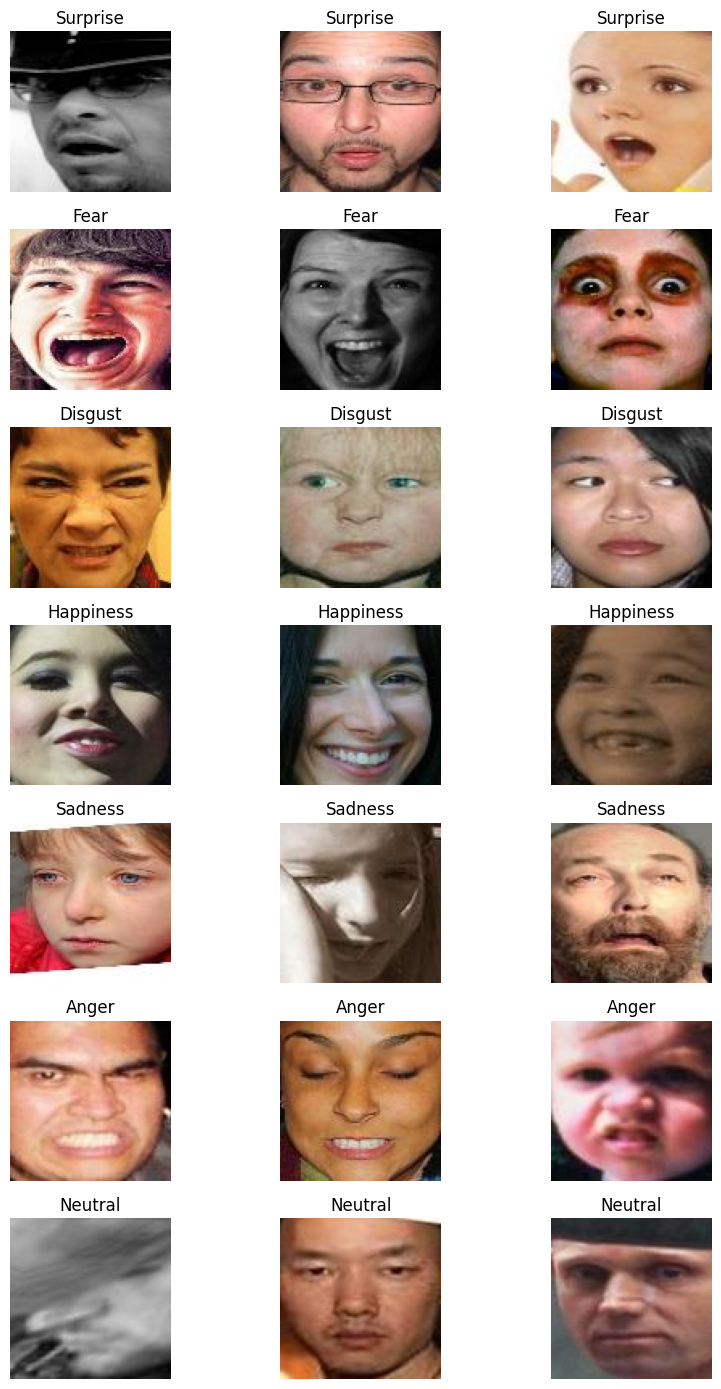

In [4]:
def plot_examples(frame: pd.DataFrame, config: Config) -> None:
    """Display native images without consuming the training loader RNG."""
    fig, axes = plt.subplots(
        len(config.class_names), config.examples_per_class,
        figsize=(3 * config.examples_per_class, 2 * len(config.class_names)),
        squeeze=False,
    )
    for target, name in enumerate(config.class_names):
        subset = frame[frame["target"] == target]
        sample = subset.sample(
            n=min(config.examples_per_class, len(subset)),
            random_state=config.seed,
        )
        for ax in axes[target]:
            ax.axis("off")
        for ax, path in zip(axes[target], sample["path"]):
            with Image.open(path) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(name)
    fig.tight_layout()
    fig.savefig(config.run_dir / "training_examples.png", dpi=150)
    plt.show()
    plt.close(fig)


if cfg.examples_per_class > 0:
    plot_examples(train_df, cfg)


### 3.2. Augmentation and DataLoaders

Use random augmentation only for training. Validation, test, and inference use
the same deterministic resize, center crop, and ImageNet normalization as the
original notebook. Store paths and targets in arrays instead of looking up a
pandas row for every sample. Pin memory only on CUDA, and set prefetch options
only when workers are enabled.

In [5]:
def make_transforms(config: Config) -> tuple[Callable, Callable]:
    """Build train augmentation and deterministic evaluation preprocessing."""
    normalize = transforms.Normalize(config.mean, config.std)
    evaluation = transforms.Compose([
        transforms.Resize(
            config.eval_resize, interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
        transforms.CenterCrop(config.image_size),
        transforms.ToTensor(), normalize,
    ])
    training = transforms.Compose([
        transforms.Resize(
            (config.image_size, config.image_size), antialias=True
        ),
        transforms.RandomHorizontalFlip(config.horizontal_flip),
        transforms.RandomRotation(config.rotation_degrees),
        transforms.ColorJitter(
            brightness=config.color_jitter, contrast=config.color_jitter,
            saturation=config.color_jitter,
        ),
        transforms.ToTensor(), normalize,
    ])
    return training, evaluation


class ExpressionDataset(Dataset):
    """Read one RGB image at a time and return a zero-based target."""

    def __init__(self, frame: pd.DataFrame, transform: Callable) -> None:
        self.paths = frame["path"].to_numpy(dtype=str, copy=True)
        self.targets = frame["target"].to_numpy(dtype=np.int64, copy=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
        with Image.open(self.paths[index]) as image:
            tensor = self.transform(image.convert("RGB"))
        return tensor, int(self.targets[index])


def seed_worker(worker_id: int) -> None:
    """Seed Python and NumPy from PyTorch's per-worker seed."""
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


def make_loader(
    frame: pd.DataFrame, transform: Callable, training: bool,
    config: Config, target_device: torch.device, seed_offset: int,
) -> DataLoader:
    """Give each loader an independent RNG and bounded prefetch queue."""
    options: dict[str, Any] = {}
    if config.num_workers > 0:
        options.update(
            persistent_workers=not config.deterministic,
            prefetch_factor=config.prefetch_factor,
        )
    return DataLoader(
        ExpressionDataset(frame, transform),
        batch_size=config.batch_size, shuffle=training, drop_last=False,
        num_workers=config.num_workers,
        pin_memory=target_device.type == "cuda",
        worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(config.seed + seed_offset),
        **options,
    )


train_transform, eval_transform = make_transforms(cfg)
train_loader = make_loader(train_df, train_transform, True, cfg, device, 0)
val_loader = make_loader(val_df, eval_transform, False, cfg, device, 1)
# Smoke-check deterministic preprocessing without advancing the train loader.
sample_tensor, sample_target = ExpressionDataset(val_df, eval_transform)[0]
if sample_tensor.shape != (3, cfg.image_size, cfg.image_size):
    raise ValueError(f"Unexpected tensor shape: {sample_tensor.shape}")
if not 0 <= sample_target < len(cfg.class_names):
    raise ValueError("Target outside expected range.")
del sample_tensor, sample_target


## 4. Model architecture

Fine-tune all ResNet-18 parameters, with a higher learning rate for the new
seven-class head. Offline initialization accepts a trusted ImageNet state
dictionary. Download errors are not silently converted into random-weight
training. Set `pretrained=False` explicitly if that is the intended experiment.

In [6]:
def build_model(config: Config, initialize: bool = True) -> nn.Module:
    """Replace the ImageNet head after optional backbone initialization."""
    weights = (
        ResNet18_Weights.DEFAULT
        if initialize and config.pretrained
        and config.local_pretrained_weights is None else None
    )
    try:
        network = resnet18(weights=weights)
    except (OSError, RuntimeError) as error:
        raise RuntimeError(
            "Pretrained initialization failed. Enable Kaggle Internet, "
            "attach local weights, or explicitly set pretrained=False."
        ) from error
    if initialize and config.pretrained and config.local_pretrained_weights:
        state = torch.load(
            config.local_pretrained_weights, map_location="cpu", weights_only=True
        )
        network.load_state_dict(state)
    network.fc = nn.Linear(network.fc.in_features, len(config.class_names))
    return network


def build_optimizer(network: nn.Module, config: Config) -> torch.optim.Optimizer:
    """Separate pretrained backbone and randomly initialized head rates."""
    backbone = [
        parameter for name, parameter in network.named_parameters()
        if not name.startswith("fc.")
    ]
    return torch.optim.AdamW([
        {"params": backbone, "lr": config.backbone_lr},
        {"params": network.fc.parameters(), "lr": config.head_lr},
    ], weight_decay=config.weight_decay)


def make_scaler(enabled: bool) -> Any:
    """Support current and older Kaggle PyTorch AMP entry points."""
    if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda", enabled=enabled)
    return torch.cuda.amp.GradScaler(enabled=enabled)


seed_everything(cfg.seed, cfg.deterministic)
model = build_model(cfg, initialize=cfg.resume_path is None).to(device)
class_weights = None
if cfg.class_weighting:
    # Estimate loss weights from training labels only, never validation/test.
    frequencies = np.bincount(train_df["target"], minlength=len(cfg.class_names))
    class_weights = torch.tensor(
        len(train_df) / (len(cfg.class_names) * frequencies),
        dtype=torch.float32, device=device,
    )
criterion = nn.CrossEntropyLoss(
    weight=class_weights, label_smoothing=cfg.label_smoothing,
)
optimizer = build_optimizer(model, cfg)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=cfg.epochs
)
scaler = make_scaler(amp_enabled)
logger.info(
    "Architecture=resnet18 | Trainable parameters=%s | AMP=%s",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}",
    amp_enabled,
)


# Run shape checks in eval mode so BatchNorm statistics are not changed.
model.eval()
with torch.inference_mode():
    smoke_input = torch.zeros(2, 3, cfg.image_size, cfg.image_size, device=device)
    smoke_logits = model(smoke_input)
    assert smoke_logits.shape == (2, len(cfg.class_names))
    assert torch.isfinite(smoke_logits).all().item()
del smoke_input, smoke_logits


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 234MB/s]
2026-11-16 18:11:34,399 | INFO | Architecture=resnet18 | Trainable parameters=11,180,103 | AMP=True


## 5. Training and validation

Accumulate detached loss and a small confusion matrix on the device rather
than retaining computation graphs or full prediction arrays. Transfer metrics
at epoch boundaries. A finite-loss check still synchronizes once per batch so
numerical failures stop immediately. Validation disables autograd.

In [7]:
def metrics_from_confusion(matrix: np.ndarray) -> dict[str, float]:
    """Compute accuracy and fixed-class macro-F1 with zero division set to 0."""
    true_positive = np.diag(matrix).astype(float)
    denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
    f1 = np.divide(
        2 * true_positive, denominator,
        out=np.zeros_like(true_positive), where=denominator != 0,
    )
    return {
        "accuracy": float(true_positive.sum() / max(matrix.sum(), 1)),
        "macro_f1": float(f1.mean()),
    }


def run_epoch(
    network: nn.Module, loader: DataLoader, loss_fn: nn.Module,
    target_device: torch.device, num_classes: int, use_amp: bool,
    optimizer: Optional[torch.optim.Optimizer] = None,
    scaler: Any = None, clip_norm: Optional[float] = None,
    description: str = "Validation",
) -> dict[str, float]:
    """Run one pass; an optimizer selects training mode."""
    training = optimizer is not None
    network.train(training)
    loss_sum = torch.zeros((), device=target_device)
    matrix = torch.zeros(
        (num_classes, num_classes), dtype=torch.int64, device=target_device
    )
    sample_count = 0
    loss_denominator = torch.zeros((), device=target_device)
    with torch.set_grad_enabled(training):
        for images, targets in tqdm(loader, desc=description, leave=False):
            images = images.to(target_device, non_blocking=True)
            targets = targets.to(target_device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                device_type=target_device.type, dtype=torch.float16,
                enabled=use_amp,
            ):
                logits = network(images)
                loss = loss_fn(logits, targets)
            if not torch.isfinite(loss).item():
                raise FloatingPointError(f"Nonfinite loss in {description}.")
            if training:
                scaler.scale(loss).backward()
                if clip_norm is not None:
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(network.parameters(), clip_norm)
                scaler.step(optimizer)
                scaler.update()
            batch_size = targets.size(0)
            sample_count += batch_size
            # CrossEntropyLoss(weight=..., reduction="mean") normalizes by
            # target weights; undo that denominator for epoch aggregation.
            denominator = (
                loss_fn.weight[targets].sum()
                if getattr(loss_fn, "weight", None) is not None
                else torch.tensor(float(batch_size), device=target_device)
            )
            loss_sum += loss.detach().float() * denominator
            loss_denominator += denominator
            indices = targets * num_classes + logits.detach().argmax(dim=1)
            matrix += torch.bincount(
                indices, minlength=num_classes**2
            ).reshape(num_classes, num_classes)
    if sample_count == 0:
        raise ValueError("Cannot evaluate an empty loader.")
    return {
        "loss": loss_sum.item() / loss_denominator.item(),
        **metrics_from_confusion(matrix.cpu().numpy()),
    }


def save_checkpoint(
    network: nn.Module, epoch: int, score: float, config: Config,
) -> None:
    """Atomically save inference weights and their preprocessing contract."""
    temporary = config.checkpoint_path.with_suffix(".tmp")
    torch.save({
        "schema_version": 2,
        "architecture": "resnet18",
        "model_state_dict": network.state_dict(),
        "class_names": list(config.class_names),
        "epoch": epoch, "val_macro_f1": float(score),
        "config": json_config(config),
        "split_signature": manifest_signature,
        "environment": environment,
        "preprocessing": {
            "image_size": config.image_size, "eval_resize": config.eval_resize,
            "mean": list(config.mean), "std": list(config.std),
            "interpolation": "bilinear", "antialias": True,
        },
    }, temporary)
    temporary.replace(config.checkpoint_path)


def atomic_torch_save(payload: dict[str, Any], destination: Path) -> None:
    """Replace a complete checkpoint only after serialization succeeds."""
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    try:
        torch.save(payload, temporary)
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)


def capture_rng(loaders: dict[str, DataLoader]) -> dict[str, Any]:
    """Use tensors and primitives compatible with weights_only=True."""
    numpy_state = np.random.get_state()
    return {
        "python": random.getstate(),
        "numpy": {
            "kind": numpy_state[0], "keys": numpy_state[1].tolist(),
            "position": numpy_state[2], "has_gauss": numpy_state[3],
            "cached_gaussian": numpy_state[4],
        },
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        "loaders": {name: loader.generator.get_state()
                    for name, loader in loaders.items()},
    }


def restore_rng(state: dict[str, Any], loaders: dict[str, DataLoader]) -> None:
    """Restore epoch-boundary RNG state after constructing training objects."""
    random.setstate(state["python"])
    numpy_state = state["numpy"]
    np.random.set_state((
        numpy_state["kind"], np.asarray(numpy_state["keys"], dtype=np.uint32),
        numpy_state["position"], numpy_state["has_gauss"],
        numpy_state["cached_gaussian"],
    ))
    torch.set_rng_state(state["torch"].cpu())
    if torch.cuda.is_available() and state["cuda"]:
        torch.cuda.set_rng_state_all([value.cpu() for value in state["cuda"]])
    for name, loader in loaders.items():
        loader.generator.set_state(state["loaders"][name].cpu())


def fit(
    network: nn.Module, training_loader: DataLoader, validation_loader: DataLoader,
    loss_fn: nn.Module, optimizer: torch.optim.Optimizer, scheduler: Any,
    scaler: Any, config: Config, target_device: torch.device,
) -> pd.DataFrame:
    """Fit or recover at epoch boundaries; select solely on validation macro-F1."""
    history: list[dict[str, Any]] = []
    best_score = -float("inf")
    patience_reference = -float("inf")
    stale_epochs, start_epoch = 0, 1
    best_payload = None
    loaders = {"train": training_loader, "validation": validation_loader}
    use_amp = config.use_amp and target_device.type == "cuda"
    if config.resume_path is not None:
        recovery = torch.load(
            config.resume_path, map_location="cpu", weights_only=True
        )
        if recovery.get("kind") != "epoch_boundary_training_v1":
            raise ValueError("Use last_training.pt, not the inference checkpoint.")
        if recovery["split_signature"] != manifest_signature:
            raise ValueError("Resume refused: dataset/split signature changed.")
        ignored = {
            "data_root", "output_root", "run_name", "resume_path",
            "allow_overwrite", "inference_image", "local_pretrained_weights",
        }
        current = json_config(config)
        changed = [key for key in current if key not in ignored
                   and current[key] != recovery["config"].get(key)]
        if changed:
            raise ValueError(f"Resume configuration changed: {changed}")
        environment_keys = (
            "python", "torch", "torchvision", "numpy", "pandas", "sklearn",
            "cuda", "cudnn", "device", "gpu",
        )
        changed_environment = [
            key for key in environment_keys
            if environment[key] != recovery["environment"].get(key)
        ]
        if changed_environment:
            raise ValueError(f"Resume environment changed: {changed_environment}")
        network.load_state_dict(recovery["model"])
        optimizer.load_state_dict(recovery["optimizer"])
        scheduler.load_state_dict(recovery["scheduler"])
        scaler.load_state_dict(recovery["scaler"])
        history = recovery["history"]
        start_epoch = recovery["epoch"] + 1
        best_score = recovery["best_score"]
        patience_reference = recovery["patience_reference"]
        stale_epochs = recovery["stale_epochs"]
        best_payload = recovery["best_inference"]
        atomic_torch_save(best_payload, config.checkpoint_path)
        restore_rng(recovery["rng"], loaders)
        del recovery
        logger.info("Recovered through epoch %d", start_epoch - 1)
    if stale_epochs >= config.patience:
        logger.info("Recovered run had already met the early-stopping rule.")
        return pd.DataFrame(history)
    for epoch in range(start_epoch, config.epochs + 1):
        start = time.perf_counter()
        if target_device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(target_device)
        rates = [group["lr"] for group in optimizer.param_groups]
        train_metrics = run_epoch(
            network, training_loader, loss_fn, target_device,
            len(config.class_names), use_amp, optimizer, scaler,
            config.gradient_clip_norm, f"Train {epoch}/{config.epochs}",
        )
        # Compare unsmoothed, unweighted validation loss across experiments.
        val_metrics = run_epoch(
            network, validation_loader, nn.CrossEntropyLoss(), target_device,
            len(config.class_names), use_amp,
            description=f"Validation {epoch}/{config.epochs}",
        )
        score = val_metrics["macro_f1"]
        improved = score > best_score
        if improved:
            best_score = score
            save_checkpoint(network, epoch, score, config)
            best_payload = torch.load(
                config.checkpoint_path, map_location="cpu", weights_only=True
            )
        if score > patience_reference + config.min_delta:
            patience_reference, stale_epochs = score, 0
        else:
            stale_epochs += 1
        row = {
            "epoch": epoch,
            **{f"train_{key}": value for key, value in train_metrics.items()},
            **{f"val_{key}": value for key, value in val_metrics.items()},
            "backbone_lr": rates[0], "head_lr": rates[1],
            "seconds": time.perf_counter() - start,
            "peak_gpu_allocated_mb": (
                torch.cuda.max_memory_allocated(target_device) / 1024**2
                if target_device.type == "cuda" else 0.0
            ),
        }
        history.append(row)
        scheduler.step()
        # The scheduler and RNG state refer to the NEXT epoch.
        atomic_torch_save({
            "kind": "epoch_boundary_training_v1", "epoch": epoch,
            "model": network.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
            "best_inference": best_payload, "best_score": best_score,
            "patience_reference": patience_reference, "stale_epochs": stale_epochs,
            "history": history, "rng": capture_rng(loaders),
            "config": json_config(config), "environment": environment,
            "split_signature": manifest_signature,
        }, config.run_dir / "last_training.pt")
        history_frame = pd.DataFrame(history)
        temporary_csv = config.run_dir / "training_history.csv.tmp"
        history_frame.to_csv(temporary_csv, index=False)
        temporary_csv.replace(config.run_dir / "training_history.csv")
        logger.info(
            "Epoch %02d/%02d | train loss %.4f | val loss %.4f | "
            "val accuracy %.4f | val macro-F1 %.4f | %.1fs%s",
            epoch, config.epochs, train_metrics["loss"], val_metrics["loss"],
            val_metrics["accuracy"], score, row["seconds"],
            " | saved best" if improved else "",
        )
        if stale_epochs >= config.patience:
            logger.info("Early stopping after %d epochs", epoch)
            break
    if not history:
        raise RuntimeError("No completed training epochs.")
    logger.info("Best validation macro-F1: %.4f", best_score)
    return pd.DataFrame(history)


### 5.0. Fast invariant checks

These lightweight checks run before training. They verify fixed-class F1,
zero-division handling, singleton dataset batches, checkpoint serialization,
and model output shape. The checkpoint round trip checks weights-only loading
without allocating a second ResNet. It does not replace a full GPU integration
or interruption/recovery test.

In [8]:
def run_invariant_checks() -> None:
    """Catch common metric, loader, and serialization regressions early."""
    from sklearn.metrics import accuracy_score, f1_score

    rng = np.random.default_rng(cfg.seed)
    targets = rng.integers(0, len(cfg.class_names), size=200)
    predicted = rng.integers(0, len(cfg.class_names), size=200)
    matrix = confusion_matrix(targets, predicted, labels=range(len(cfg.class_names)))
    computed = metrics_from_confusion(matrix)
    assert np.isclose(computed["accuracy"], accuracy_score(targets, predicted))
    assert np.isclose(computed["macro_f1"], f1_score(
        targets, predicted, average="macro", labels=range(len(cfg.class_names)),
        zero_division=0,
    ))
    assert metrics_from_confusion(np.zeros((7, 7), dtype=int))["macro_f1"] == 0
    one = ExpressionDataset(val_df.iloc[:1], eval_transform)
    image, target = one[0]
    assert image.shape == (3, cfg.image_size, cfg.image_size)
    assert image.dtype == torch.float32
    assert 0 <= target < len(cfg.class_names)
    temporary = cfg.run_dir / ".serialization_check.pt"
    try:
        atomic_torch_save({"tensor": torch.arange(3)}, temporary)
        restored = torch.load(temporary, map_location="cpu", weights_only=True)
        assert torch.equal(restored["tensor"], torch.arange(3))
    finally:
        temporary.unlink(missing_ok=True)
    logger.info("Metric, dataset, shape, and serialization invariants passed.")


run_invariant_checks()


2026-11-16 18:11:39,088 | INFO | Metric, dataset, shape, and serialization invariants passed.


### 5.1. Fit or resume

Run once per initialized experiment. `best_resnet18.pt` is the inference
checkpoint selected by validation macro-F1. `last_training.pt` additionally
contains optimizer, scheduler, scaler, early-stopping state, best weights,
history, RNG states, and loader generators. Recovery is at completed epoch
boundaries, not mid-batch. Checkpoints are written to a temporary file and
atomically replaced. Epoch timings exclude the full recovery-checkpoint write.

For recovery, use a fresh session and set `resume_path` before running all
cells. Use the same epoch budget and configuration, not a new schedule.
Cross-platform bitwise reproducibility is not guaranteed.


In [9]:
history_df = fit(
    model, train_loader, val_loader, criterion, optimizer, scheduler,
    scaler, cfg, device,
)


Train 1/10:   0%|          | 0/326 [00:00<?, ?it/s]

Validation 1/10:   0%|          | 0/58 [00:00<?, ?it/s]

2026-11-16 18:12:55,391 | INFO | Epoch 01/10 | train loss 0.9558 | val loss 0.8017 | val accuracy 0.7175 | val macro-F1 0.5599 | 76.1s | saved best


Train 2/10:   0%|          | 0/326 [00:00<?, ?it/s]

Validation 2/10:   0%|          | 0/58 [00:00<?, ?it/s]

2026-11-16 18:14:12,627 | INFO | Epoch 02/10 | train loss 0.6153 | val loss 0.6607 | val accuracy 0.7670 | val macro-F1 0.6413 | 77.0s | saved best


... (8 outputs left out)

2026-11-16 18:17:48,356 | INFO | Epoch 05/10 | train loss 0.2533 | val loss 0.7209 | val accuracy 0.7816 | val macro-F1 0.6818 | 71.8s


Train 6/10:   0%|          | 0/326 [00:00<?, ?it/s]

Validation 6/10:   0%|          | 0/58 [00:00<?, ?it/s]

2026-11-16 18:19:01,339 | INFO | Epoch 06/10 | train loss 0.1852 | val loss 0.7348 | val accuracy 0.7876 | val macro-F1 0.6913 | 72.8s
2026-11-16 18:19:01,340 | INFO | Early stopping after 6 epochs
2026-11-16 18:19:01,340 | INFO | Best validation macro-F1: 0.7046


### 5.2. Learning curves

Save loss, accuracy, and macro-F1 curves alongside the per-epoch CSV. Compare
training and validation trajectories rather than inspecting test results
during model development.

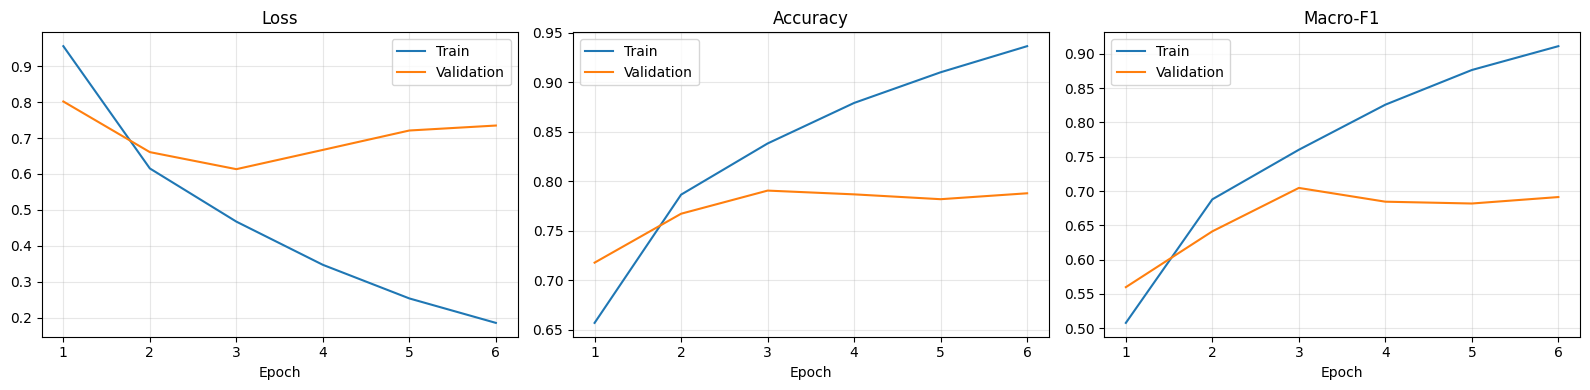

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,backbone_lr,head_lr,seconds,peak_gpu_allocated_mb
0,1,0.9558,0.6567,0.5078,0.8017,0.7175,0.5599,0.0001,0.0010,76.0922,620.6162
1,2,0.6153,0.7862,0.6880,0.6607,0.7670,0.6413,0.0001,0.0010,77.0247,620.6162
2,3,0.4672,0.8379,0.7602,0.6133,0.7903,0.7046,0.0001,0.0009,71.5492,620.6162
3,4,0.3469,0.8789,0.8260,0.6669,0.7865,0.6845,0.0001,0.0008,71.7744,620.6162
4,5,0.2533,0.9099,0.8765,0.7209,0.7816,0.6818,0.0001,0.0007,71.7686,620.6162
5,6,0.1852,0.9362,0.9113,0.7348,0.7876,0.6913,0.0000,0.0005,72.7642,620.6162


In [10]:
def plot_history(history: pd.DataFrame, destination: Path) -> None:
    """Plot the metrics recorded by fit."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, metric, title in zip(
        axes, ("loss", "accuracy", "macro_f1"),
        ("Loss", "Accuracy", "Macro-F1"),
    ):
        for prefix, label in (("train", "Train"), ("val", "Validation")):
            ax.plot(history["epoch"], history[f"{prefix}_{metric}"], label=label)
        ax.set(title=title, xlabel="Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(destination, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_history(history_df, cfg.run_dir / "learning_curves.png")
display(history_df.round(4))


## 6. Held-out evaluation

Release optimizer state before loading the validation-selected checkpoint.
Cache clearing is done at this phase boundary, not inside the training loop;
it cannot free tensors that still have live references. Reconstruct inference
preprocessing from the checkpoint rather than the current configuration.
The test report includes per-class metrics, confusion matrices, and ordered
class probabilities for error analysis.

2026-11-16 18:19:02,770 | INFO | Evaluating checkpoint from epoch 3


Held-out test:   0%|          | 0/96 [00:00<?, ?it/s]

2026-11-16 18:19:15,137 | INFO | Held-out test metrics: {'accuracy': 0.7878096479791395, 'macro_f1': 0.703129324863653, 'balanced_accuracy': 0.6877746426723041, 'negative_log_likelihood': 0.5855520963668823, 'multiclass_brier_score': 0.29421698388088985}


,precision,recall,f1-score,support
Surprise,0.8467,0.7720,0.8076,329.0000
Fear,0.5974,0.6216,0.6093,74.0000
Disgust,0.4957,0.3562,0.4145,160.0000
Happiness,0.8425,0.9257,0.8822,1185.0000
Sadness,0.7735,0.7071,0.7388,478.0000
Anger,0.7730,0.6728,0.7195,162.0000
Neutral,0.7414,0.7588,0.7500,680.0000
accuracy,0.7878,0.7878,0.7878,0.7878
macro avg,0.7243,0.6878,0.7031,3068.0000
weighted avg,0.7821,0.7878,0.7830,3068.0000


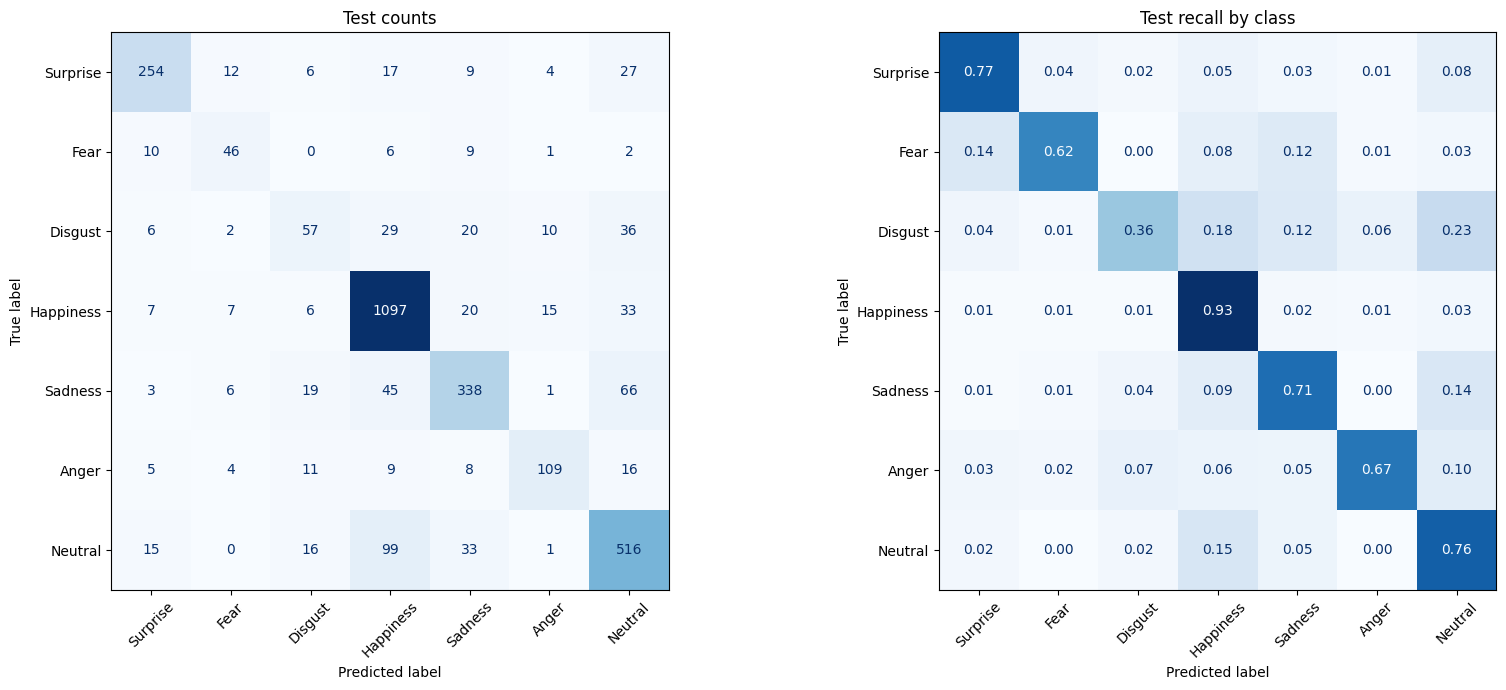

In [11]:
optimizer.zero_grad(set_to_none=True)
del optimizer, scheduler, scaler, model, train_loader, val_loader
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()


def load_predictor(
    checkpoint_path: Path, target_device: torch.device,
) -> tuple[nn.Module, Callable, list[str], dict[str, Any]]:
    """Load this notebook's tensor-only-compatible inference checkpoint."""
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    if checkpoint["architecture"] != "resnet18":
        raise ValueError("Unsupported checkpoint architecture.")
    names = checkpoint["class_names"]
    network = resnet18(weights=None)
    network.fc = nn.Linear(network.fc.in_features, len(names))
    network.load_state_dict(checkpoint["model_state_dict"])
    prep = checkpoint["preprocessing"]
    preprocessing = transforms.Compose([
        transforms.Resize(
            prep["eval_resize"], interpolation=InterpolationMode.BILINEAR,
            antialias=prep["antialias"],
        ),
        transforms.CenterCrop(prep["image_size"]),
        transforms.ToTensor(),
        transforms.Normalize(prep["mean"], prep["std"]),
    ])
    metadata = {key: value for key, value in checkpoint.items()
                if key != "model_state_dict"}
    return network.to(target_device).eval(), preprocessing, names, metadata


@torch.inference_mode()
def predict_loader(
    network: nn.Module, loader: DataLoader, target_device: torch.device,
) -> tuple[np.ndarray, np.ndarray]:
    """Return CPU targets and probabilities without retaining GPU outputs."""
    network.eval()
    targets_list, probabilities = [], []
    for images, targets in tqdm(loader, desc="Held-out test", leave=False):
        logits = network(images.to(target_device, non_blocking=True))
        probabilities.append(logits.float().softmax(dim=1).cpu().numpy())
        targets_list.append(targets.numpy())
    return np.concatenate(targets_list), np.concatenate(probabilities)


best_model, inference_transform, class_names, checkpoint_metadata = load_predictor(
    cfg.checkpoint_path, device
)
if class_names != list(cfg.class_names):
    raise ValueError("Checkpoint class order differs from the dataset mapping.")
logger.info("Evaluating checkpoint from epoch %d", checkpoint_metadata["epoch"])
test_loader = make_loader(test_df, inference_transform, False, cfg, device, 2)
y_true, probabilities = predict_loader(best_model, test_loader, device)
y_pred = probabilities.argmax(axis=1)
labels = list(range(len(class_names)))
matrix = confusion_matrix(y_true, y_pred, labels=labels)
test_metrics = metrics_from_confusion(matrix)
test_metrics.update({
    "balanced_accuracy": float(np.mean(
        np.diag(matrix) / np.maximum(matrix.sum(axis=1), 1)
    )),
    "negative_log_likelihood": float(-np.log(
        np.clip(probabilities[np.arange(len(y_true)), y_true], 1e-12, 1.0)
    ).mean()),
    # Multiclass Brier score = sum of squared probability errors per image.
    "multiclass_brier_score": float(np.square(
        probabilities - np.eye(len(class_names))[y_true]
    ).sum(axis=1).mean()),
})
report = classification_report(
    y_true, y_pred, labels=labels, target_names=class_names,
    output_dict=True, zero_division=0,
)
report_df = pd.DataFrame(report).T
report_df.to_csv(cfg.run_dir / "test_classification_report.csv")
(cfg.run_dir / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2), encoding="utf-8"
)
predictions_df = test_df[["image", "label", "expression", "target"]].copy()
predictions_df["predicted_target"] = y_pred
predictions_df["predicted_label"] = y_pred + 1
predictions_df["predicted_expression"] = np.asarray(class_names)[y_pred]
predictions_df["confidence"] = probabilities.max(axis=1)
for target, name in enumerate(class_names):
    predictions_df[f"probability_{name.lower()}"] = probabilities[:, target]
predictions_df.to_csv(cfg.run_dir / "test_predictions.csv", index=False)
pd.DataFrame(matrix, index=class_names, columns=class_names).to_csv(
    cfg.run_dir / "test_confusion_matrix.csv"
)
logger.info("Held-out test metrics: %s", test_metrics)
display(report_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
row_totals = matrix.sum(axis=1, keepdims=True)
normalized = np.divide(
    matrix, row_totals, out=np.zeros_like(matrix, dtype=float),
    where=row_totals != 0,
)
for ax, values, title, fmt in zip(
    axes, (matrix, normalized), ("Test counts", "Test recall by class"),
    ("d", ".2f"),
):
    ConfusionMatrixDisplay(values, display_labels=class_names).plot(
        ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False,
        values_format=fmt,
    )
    ax.set_title(title)
fig.tight_layout()
fig.savefig(cfg.run_dir / "test_confusion_matrix.png", dpi=150)
plt.show()
plt.close(fig)


## 7. Uncertainty, calibration, and error analysis

Report paired image-level bootstrap percentile intervals for accuracy and
macro-F1 using fixed class labels. These intervals describe finite-test-sample
variation for this trained model; they exclude training-seed variation and
assume independent images. Without subject IDs, that assumption cannot be
verified. The analysis uses a local RNG and cannot alter the training RNG.

A reliability diagram compares confidence with observed accuracy in ten
fixed-width bins. Expected calibration error (ECE) depends on the binning;
raw softmax scores are not calibrated probabilities. No calibrator or model
is fitted on test labels. Error examples are descriptive only.

,metric,estimate,lower,upper,confidence_level,bootstrap_repeats
0,accuracy,0.7878,0.7725,0.8018,0.95,1000
1,macro_f1,0.7031,0.6804,0.7241,0.95,1000


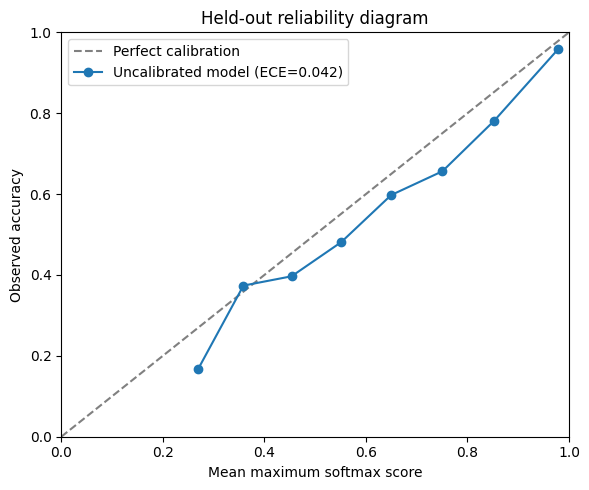

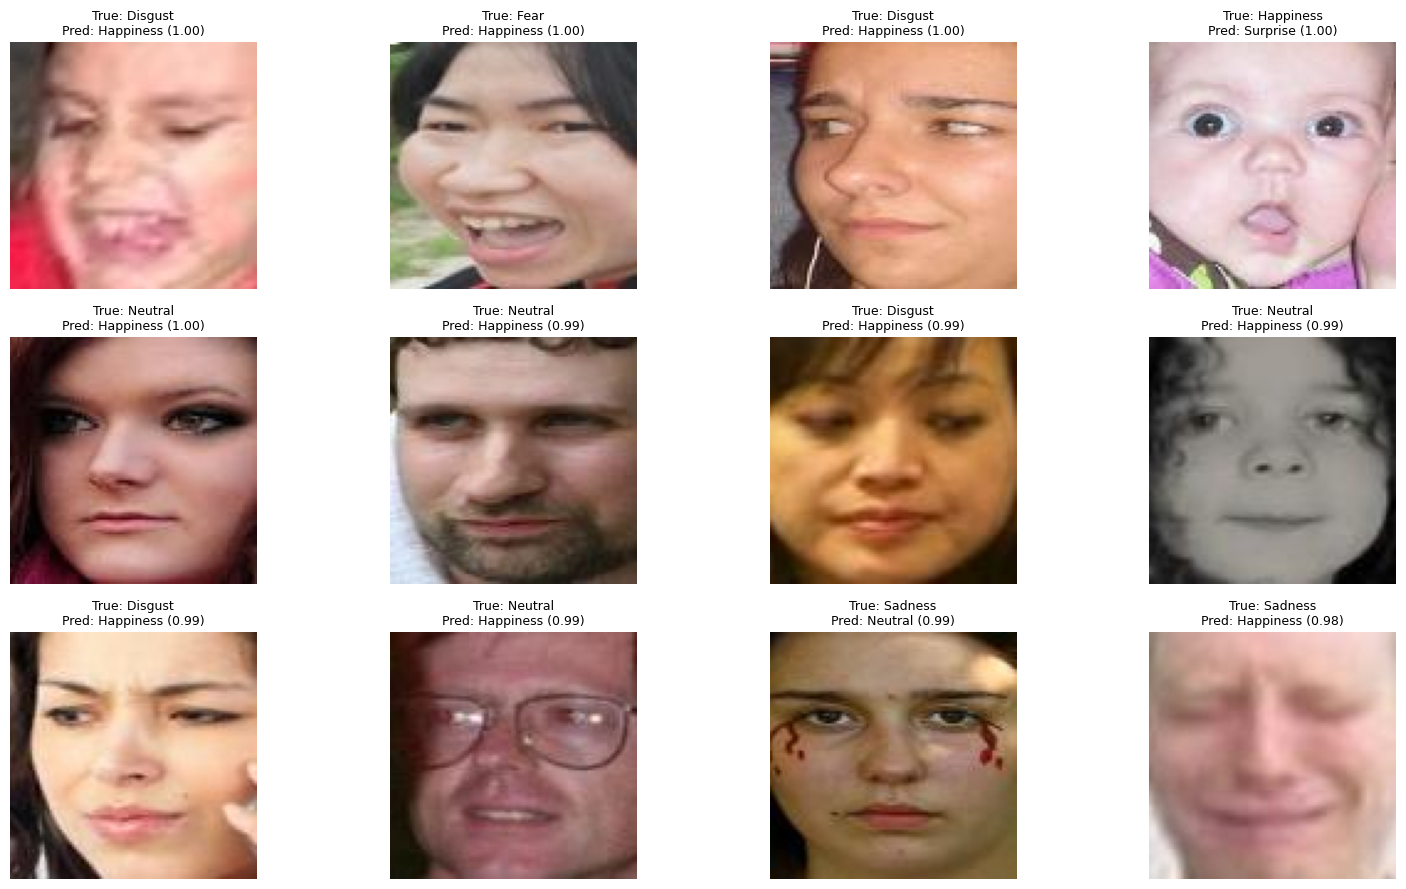

In [12]:
def bootstrap_metrics(
    targets: np.ndarray, predictions: np.ndarray, num_classes: int,
    repeats: int, confidence: float, seed: int,
) -> pd.DataFrame:
    """Paired nonparametric bootstrap with a fixed seven-class F1 definition."""
    rng = np.random.default_rng(seed)
    scores = {"accuracy": [], "macro_f1": []}
    n = len(targets)
    if n == 0:
        raise ValueError("Bootstrap requires a nonempty test set.")
    for _ in range(repeats):
        indices = rng.integers(0, n, size=n)
        encoded = targets[indices] * num_classes + predictions[indices]
        matrix = np.bincount(encoded, minlength=num_classes**2).reshape(
            num_classes, num_classes
        )
        values = metrics_from_confusion(matrix)
        for name in scores:
            scores[name].append(values[name])
    alpha = (1 - confidence) / 2
    point_matrix = np.bincount(
        targets * num_classes + predictions, minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    point_estimates = metrics_from_confusion(point_matrix)
    return pd.DataFrame([
        {"metric": name, "estimate": point_estimates[name],
         "lower": float(np.quantile(values, alpha)),
         "upper": float(np.quantile(values, 1 - alpha)),
         "confidence_level": confidence, "bootstrap_repeats": repeats}
        for name, values in scores.items()
    ])


def reliability_table(
    targets: np.ndarray, scores: np.ndarray, bins: int = 10,
) -> tuple[pd.DataFrame, float]:
    """Include confidence 1.0 in the final equal-width confidence bin."""
    confidence = scores.max(axis=1)
    correct = scores.argmax(axis=1) == targets
    assignments = np.minimum((confidence * bins).astype(int), bins - 1)
    rows = []
    for index in range(bins):
        mask = assignments == index
        count = int(mask.sum())
        rows.append({
            "lower": index / bins, "upper": (index + 1) / bins,
            "count": count,
            "mean_confidence": float(confidence[mask].mean()) if count else np.nan,
            "accuracy": float(correct[mask].mean()) if count else np.nan,
        })
    table = pd.DataFrame(rows)
    nonempty = table[table["count"] > 0]
    ece = float((
        nonempty["count"] / len(targets)
        * (nonempty["accuracy"] - nonempty["mean_confidence"]).abs()
    ).sum())
    return table, ece


intervals_df = bootstrap_metrics(
    y_true, y_pred, len(class_names), cfg.bootstrap_repeats,
    cfg.confidence_level, cfg.seed,
)
intervals_df.to_csv(cfg.run_dir / "test_bootstrap_intervals.csv", index=False)
display(intervals_df.round(4))
calibration_df, ece = reliability_table(y_true, probabilities)
calibration_df.to_csv(cfg.run_dir / "test_reliability_bins.csv", index=False)
test_metrics["ece_10_equal_width_bins"] = ece
(cfg.run_dir / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2), encoding="utf-8"
)
fig, ax = plt.subplots(figsize=(6, 5))
nonempty_bins = calibration_df[calibration_df["count"] > 0]
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.plot(
    nonempty_bins["mean_confidence"], nonempty_bins["accuracy"],
    "o-", label=f"Uncalibrated model (ECE={ece:.3f})",
)
ax.set(xlabel="Mean maximum softmax score", ylabel="Observed accuracy",
       xlim=(0, 1), ylim=(0, 1), title="Held-out reliability diagram")
ax.legend()
fig.tight_layout()
fig.savefig(cfg.run_dir / "test_reliability.png", dpi=150)
plt.show()
plt.close(fig)

# Highest-confidence errors are useful for finding annotation/model failures.
error_indices = np.flatnonzero(y_true != y_pred)
error_indices = error_indices[
    np.argsort(-probabilities[error_indices].max(axis=1), kind="stable")
][:cfg.error_examples]
if len(error_indices):
    columns = min(4, len(error_indices))
    rows = (len(error_indices) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3 * rows),
                             squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, error_indices):
        with Image.open(test_df.iloc[index]["path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(
            f"True: {class_names[y_true[index]]}\n"
            f"Pred: {class_names[y_pred[index]]} "
            f"({probabilities[index].max():.2f})", fontsize=9,
        )
    fig.tight_layout()
    fig.savefig(cfg.run_dir / "test_high_confidence_errors.png", dpi=150)
    plt.show()
    plt.close(fig)


## 8. Single-image inference

Predict an already cropped/aligned face using the saved evaluation transform.
This classifier does not perform face detection or alignment. The output is a
model score over expression labels, not a calibrated measure of emotion.
Set `Config.inference_image` for your own image; otherwise the example uses
the first held-out image after evaluation.

In [13]:
@torch.inference_mode()
def predict_image(
    image_path: Path, network: nn.Module, preprocessing: Callable,
    names: list[str], target_device: torch.device, top_k: int,
) -> pd.DataFrame:
    """Return the top expression labels for one cropped RGB face."""
    if not 1 <= top_k <= len(names):
        raise ValueError("top_k must be between 1 and the number of classes.")
    network.eval()
    with Image.open(image_path) as image:
        tensor = preprocessing(image.convert("RGB")).unsqueeze(0)
    scores = network(tensor.to(target_device)).float().softmax(dim=1)[0]
    values, indices = scores.topk(top_k)
    targets = indices.cpu().tolist()
    return pd.DataFrame({
        "target": targets,
        "dataset_label": [target + 1 for target in targets],
        "expression": [names[target] for target in targets],
        "probability": values.cpu().tolist(),
    })


inference_path = cfg.inference_image or Path(test_df.iloc[0]["path"])
display(predict_image(
    inference_path, best_model, inference_transform,
    class_names, device, cfg.inference_top_k,
))


,target,dataset_label,expression,probability
0,4,5,Sadness,0.794317
1,6,7,Neutral,0.185784
2,2,3,Disgust,0.012519


## 9. Portable inference export and model card

Export a standalone Python predictor with a small command-line interface.
Its only dependencies are PyTorch, torchvision, Pillow, and pandas. Both the
class order and preprocessing are loaded from the checkpoint. No dataset,
training optimizer, or hard-coded Kaggle input path is used by the predictor.
The model card records the actual run metrics and limitations, not a claim
that this model is suitable for deployment in high-stakes settings.

In [14]:
# Export the same inference implementations used above, without notebook state.
predictor_imports = """from __future__ import annotations
import argparse
from pathlib import Path
from typing import Any, Callable
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torchvision import transforms
from torchvision.models import resnet18
from torchvision.transforms import InterpolationMode
"""
predictor_main = """

def main() -> None:
    parser = argparse.ArgumentParser(description="RAF-DB expression inference")
    parser.add_argument("checkpoint", type=Path)
    parser.add_argument("image", type=Path)
    parser.add_argument("--top-k", type=int, default=3)
    parser.add_argument("--device", choices=["auto", "cpu", "cuda"], default="auto")
    parser.add_argument("--output", type=Path)
    args = parser.parse_args()
    selected = (
        "cuda" if torch.cuda.is_available() else "cpu"
    ) if args.device == "auto" else args.device
    device = torch.device(selected)
    model, preprocessing, names, _ = load_predictor(args.checkpoint, device)
    result = predict_image(args.image, model, preprocessing, names,
                           device, args.top_k)
    if args.output:
        result.to_csv(args.output, index=False)
    print(result.to_string(index=False))


if __name__ == "__main__":
    main()
"""
predictor_source = (
    predictor_imports + "\n\n" + '''
def load_predictor(
    checkpoint_path: Path, target_device: torch.device,
) -> tuple[nn.Module, Callable, list[str], dict[str, Any]]:
    """Load this notebook's tensor-only-compatible inference checkpoint."""
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    if checkpoint["architecture"] != "resnet18":
        raise ValueError("Unsupported checkpoint architecture.")
    names = checkpoint["class_names"]
    network = resnet18(weights=None)
    network.fc = nn.Linear(network.fc.in_features, len(names))
    network.load_state_dict(checkpoint["model_state_dict"])
    prep = checkpoint["preprocessing"]
    preprocessing = transforms.Compose([
        transforms.Resize(
            prep["eval_resize"], interpolation=InterpolationMode.BILINEAR,
            antialias=prep["antialias"],
        ),
        transforms.CenterCrop(prep["image_size"]),
        transforms.ToTensor(),
        transforms.Normalize(prep["mean"], prep["std"]),
    ])
    metadata = {key: value for key, value in checkpoint.items()
                if key != "model_state_dict"}
    return network.to(target_device).eval(), preprocessing, names, metadata
'''
    + "\n\n" + '''
@torch.inference_mode()
def predict_image(
    image_path: Path, network: nn.Module, preprocessing: Callable,
    names: list[str], target_device: torch.device, top_k: int,
) -> pd.DataFrame:
    """Return the top expression labels for one cropped RGB face."""
    if not 1 <= top_k <= len(names):
        raise ValueError("top_k must be between 1 and the number of classes.")
    network.eval()
    with Image.open(image_path) as image:
        tensor = preprocessing(image.convert("RGB")).unsqueeze(0)
    scores = network(tensor.to(target_device)).float().softmax(dim=1)[0]
    values, indices = scores.topk(top_k)
    targets = indices.cpu().tolist()
    return pd.DataFrame({
        "target": targets,
        "dataset_label": [target + 1 for target in targets],
        "expression": [names[target] for target in targets],
        "probability": values.cpu().tolist(),
    })
''' + predictor_main
)
compile(predictor_source, "predictor.py", "exec")
(cfg.run_dir / "predictor.py").write_text(predictor_source, encoding="utf-8")

model_card = f"""# RAF-DB ResNet-18 model card

## Intended use
Research on seven-class facial-expression classification of cropped/aligned
RGB face images with the same preprocessing and label mapping as this run.
Not a face detector, identity recognizer, or measurement of internal emotion.
Not validated for clinical, employment, education, policing, or other
high-stakes decisions about people.

## Training and selection
- Architecture: ResNet-18; all parameters fine-tuned.
- Classes, in target order: {', '.join(class_names)}.
- Training / validation / test: {len(train_df)} / {len(val_df)} / {len(test_df)}.
- Selected epoch: {checkpoint_metadata['epoch']}.
- Selected validation macro-F1: {checkpoint_metadata['val_macro_f1']:.4f}.
- Split signature: {manifest_signature}.
- Loss weighting: {cfg.class_weighting}; label smoothing: {cfg.label_smoothing}.

## Held-out evaluation
- Accuracy: {test_metrics['accuracy']:.4f}.
- Macro-F1: {test_metrics['macro_f1']:.4f}.
- Balanced accuracy: {test_metrics['balanced_accuracy']:.4f}.
- ECE (10 fixed-width confidence bins): {ece:.4f}.
- Bootstrap intervals: see test_bootstrap_intervals.csv. These cover image
  sampling variation only, not repeated training runs or domain shift.

## Limitations and governance
No subject IDs were provided; identity-independent splits cannot be verified.
Exact RGB duplicates are audited; near-duplicates and demographic fairness
have not been established. Scores are uncalibrated. Test examples and metrics
must not be reused for model-selection decisions. Check source dataset
licensing, consent, and redistribution restrictions before sharing artifacts.
No license for dataset images or pretrained weights is granted by this card.

## Inference
python predictor.py best_resnet18.pt cropped_face.jpg --top-k 3

Use only trusted checkpoint files. Recovery checkpoints are not predictor
inputs. Consult config.json and environment.json for experiment settings.
"""
(cfg.run_dir / "MODEL_CARD.md").write_text(model_card, encoding="utf-8")


1800

## 10. Artifact inventory and reproducibility record

Use `best_resnet18.pt` for inference and `last_training.pt` for recovery.
The latter is larger because it includes optimizer state and the selected
best inference payload. `split_manifest.csv`, its signature, configuration,
environment snapshot, and logs document the experiment. The final artifact
manifest includes SHA-256 checksums; the active log is excluded because it can
change while the session is open.

`test_predictions.csv` is an analysis artifact, not a Kaggle submission file.
No competition-specific submission schema has been supplied. Do not publish
image-derived artifacts without checking the dataset's licensing and consent
requirements.


In [15]:
def sha256_file(path: Path) -> str:
    """Hash in chunks to avoid loading large checkpoints into RAM."""
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


artifacts = pd.DataFrame([
    {"artifact": path.name, "bytes": path.stat().st_size,
     "sha256": sha256_file(path)}
    for path in sorted(cfg.run_dir.iterdir())
    if path.is_file() and path.name not in {"artifact_manifest.csv", "training.log"}
])
artifacts.to_csv(cfg.run_dir / "artifact_manifest.csv", index=False)
display(artifacts)
logger.info("Artifacts saved under %s", cfg.run_dir)
# Keep best_model available for inference; release test loader references.
del test_loader
gc.collect()


,artifact,bytes,sha256
0,MODEL_CARD.md,1800,f08634637b4917d4f337e1c78b1dc59e40d4b7e4dc100a...
1,best_resnet18.pt,44802955,e305eab51745116c8e5d39b1d5e7b47fc772293ab3c509...
2,config.json,1415,1269d3230a3f7057c85bdd6000f48c1f8623e14a2e9b5b...
3,duplicate_audit.csv,430,e017884324c03512a534163f03cb5923c20ad577ce3e39...
4,environment.json,225,4e5443769128a3b9da900c710a3187776b525b8630a56e...
5,last_training.pt,179126298,6164954b99f68a2d7e7ee0019ca9e34aad1921d13af4f0...
6,learning_curves.png,104911,3924e0a0f2efed6a0dad56937311d283da16bf9361eb44...
7,predictor.py,3301,9342a4bf0fdee88794af14a9849074a7cce62ea304c3ea...
8,split_manifest.csv,2256122,7043bc3e1f0986b49841db62f261937a95eeb3814b5b62...
9,split_signature.txt,65,ddd9c61ed79c828b99fff3d13d2eb96629ce6da497a273...


2026-11-16 18:19:18,824 | INFO | Artifacts saved under /kaggle/working/raf_expression/resnet18_professional_seed42


14016

## 11. Implementation notes

- [PyTorch reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html):
  RNG seeding and independent DataLoader generators; portability limitations.
- [Checkpointing](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html):
  distinguish inference state dictionaries from resumable training state.
- [PyTorch DataLoader](https://docs.pytorch.org/docs/stable/data.html):
  worker configuration, seeding, and pinned memory.

Before claiming an improvement, compare repeated validation runs under the
same split and training budget. Optional loss changes are not enabled by
default. This notebook does not claim higher accuracy or faster training than
the supplied run. The historical run's outputs remain in the original file;
they are not presented as results from this revision.